# Step 2 – Concentrazione del settore quantum computing

Notebook basato su **11 · Competitive landscape** (sezioni 3 e 5.1), applicato alle famiglie già selezionate negli step 0.

| Cella | Contenuto |
|---|---|
| 1 | Setup e caricamento delle famiglie dagli step 0 |
| 2 | Anno e titolari (applicant) di ogni famiglia |
| 3 | Armonizzazione dei nomi (dizionario, oppure file del collega) |
| 4 | Famiglie per applicant |
| 5 | Anno di split |
| 6 | Funzioni delle metriche (copiate dal notebook 11) |
| 7–10 | CR4, CR8, HH, 1/HH per anno |
| 11–13 | CV, Lorenz + Gini, Lotka su tutto il periodo |

**Unità di conteggio**: la famiglia DOCDB. Ogni famiglia conta **una volta per ciascun titolare**; se ha più co-titolari conta una volta per ognuno, come nel notebook 11.

## 1. Setup e caricamento delle famiglie

Stessa struttura di `validation_step0`: si leggono gli id delle famiglie salvati dagli step 0, senza rilanciare la query di settore.

In [9]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from scipy import stats                      # regressione per Lotka
from sqlalchemy import func

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,               # application (famiglia, anno)
    TLS206_PERSON,              # persone: nome standardizzato PATSTAT (psn_name)
    TLS207_PERS_APPLN,          # legame persona <-> application (applicant / inventor)
)

# "v1" = step0.ipynb | "v2" = step0_complex_version.ipynb
SOURCE = "v1"
ENV = "PROD"                         # "TEST" per le prove, "PROD" per i numeri finali

YEAR_MIN, YEAR_MAX = 2010, 2023      # periodo di analisi (anno di priorità più antico della famiglia)
LAST_COMPLETE_YEAR = 2021            # gli anni successivi sono incompleti in PATSTAT (ritardo di pubblicazione ~18 mesi)

# File salvati dagli step 0
SECTOR_FILES = {
    "v1": Path("/home/jovyan/Group15_innovation/step0-1/outputs/step0/sector_ids.parquet"),
    "v2": Path(f"outputs/step0_epo/qc_families_v2_{ENV}.csv"),
}


def load_sector_ids(path):
    """Legge parquet o csv e restituisce un DataFrame con la sola colonna 'docdb_family_id'.
    In step0.ipynb la union di SQLAlchemy rinomina la colonna (es. 'anon_1_docdb_family_id'),
    quindi si prende la prima colonna qualunque sia il suo nome."""
    df = pd.read_parquet(path) if path.suffix == ".parquet" else pd.read_csv(path)
    return df.iloc[:, [0]].set_axis(["docdb_family_id"], axis=1)


sector_ids = load_sector_ids(SECTOR_FILES[SOURCE])
family_ids = sector_ids["docdb_family_id"].dropna().astype(int).unique().tolist()

# Output separati per versione
OUTPUT_DIR = Path(f"outputs/step2_{SOURCE}")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

patstat = PatstatClient(env=ENV)
db = patstat.orm()

print(f"Sorgente: {SOURCE} | file: {SECTOR_FILES[SOURCE]} | famiglie nel file: {len(family_ids):,}")

Sorgente: v1 | file: /home/jovyan/Group15_innovation/step0-1/outputs/step0/sector_ids.parquet | famiglie nel file: 13,523


## 2. Anno e titolari di ogni famiglia

- **Anno della famiglia**: il minimo di `earliest_filing_year` fra tutte le sue application (come nel notebook 11).
- **Titolari**: le persone con `applt_seq_nr > 0` in `TLS207` (gli inventori hanno `applt_seq_nr = 0` e restano fuori).

Gli id vengono passati a PATSTAT a blocchi di `CHUNK` per non creare una condizione `IN` troppo lunga. La cella salva anche la lista dei `psn_name` del settore, da dare al collega come input per l'armonizzazione.

In [10]:
CHUNK = 5000


def chunks(values, size):
    for start in range(0, len(values), size):
        yield values[start:start + size]


years, applicants = [], []
for ids in chunks(family_ids, CHUNK):
    # anno della famiglia: il più antico fra le sue application (9999 = anno mancante in PATSTAT)
    q_year = (
        db.query(TLS201_APPLN.docdb_family_id.label("family_id"),
                 func.min(TLS201_APPLN.earliest_filing_year).label("year"))
        .filter(TLS201_APPLN.docdb_family_id.in_(ids),
                TLS201_APPLN.earliest_filing_year < 9999)
        .group_by(TLS201_APPLN.docdb_family_id)
    )
    years.append(patstat.df(q_year))

    # titolari: una riga per famiglia e persona
    q_app = (
        db.query(TLS201_APPLN.docdb_family_id.label("family_id"),
                 TLS206_PERSON.psn_id,
                 TLS206_PERSON.psn_name)
        .join(TLS207_PERS_APPLN, TLS207_PERS_APPLN.appln_id == TLS201_APPLN.appln_id)
        .join(TLS206_PERSON, TLS206_PERSON.person_id == TLS207_PERS_APPLN.person_id)
        .filter(TLS201_APPLN.docdb_family_id.in_(ids),
                TLS207_PERS_APPLN.applt_seq_nr > 0)          # solo applicant, niente inventori
        .distinct()
    )
    applicants.append(patstat.df(q_app))

family_year = pd.concat(years, ignore_index=True)
family_year = family_year[family_year["year"].between(YEAR_MIN, YEAR_MAX)]

raw_applicants = pd.concat(applicants, ignore_index=True)
raw_applicants = raw_applicants[raw_applicants["family_id"].isin(family_year["family_id"])]

no_applicant = set(family_year["family_id"]) - set(raw_applicants["family_id"])

# lista dei nomi del settore per il collega: psn_name e numero di famiglie in cui compare
psn_names = (raw_applicants.groupby("psn_name")["family_id"].nunique()
             .rename("families").sort_values(ascending=False).reset_index())
psn_names.to_csv(OUTPUT_DIR / "psn_names_for_harmonisation.csv", index=False)

print(f"Famiglie {YEAR_MIN}-{YEAR_MAX}: {family_year['family_id'].nunique():,}")
print(f"Famiglie senza titolare in PATSTAT (escluse dalle metriche): {len(no_applicant):,}")
print(f"Nomi PATSTAT distinti (psn_name): {len(psn_names):,} -> {OUTPUT_DIR / 'psn_names_for_harmonisation.csv'}")

Famiglie 2010-2023: 11,570
Famiglie senza titolare in PATSTAT (escluse dalle metriche): 10
Nomi PATSTAT distinti (psn_name): 4,648 -> outputs/step2_v1/psn_names_for_harmonisation.csv


## 3. Armonizzazione dei nomi

La funzione `harmonise` restituisce il dizionario `psn_name -> applicant` (nome armonizzato).

- **Se esiste `name_mapping.csv`** (prodotto dal notebook del collega, con colonne `psn_name` e `applicant`), usa quello. I nomi che non compaiono nel file ricadono sul metodo a dizionario.
- **Altrimenti** usa il metodo a dizionario del notebook 11: maiuscole, solo lettere e cifre, rimozione delle forme legali (INC, LTD, CORP, GMBH…) all'inizio e alla fine.

> Embedding, grafo e Louvain restano nel notebook del collega: qui si legge solo il risultato.

In [11]:
MAPPING_FILE = OUTPUT_DIR / "name_mapping.csv"     # colonne: psn_name, applicant

# Forme legali da rimuovere (dal notebook 11; estendere per i paesi del settore)
LEGAL_FORMS = {
    "INC", "INCORPORATED", "CORP", "CORPORATION", "CO", "COMPANY", "LTD", "LIMITED", "LLC", "LP", "PLC",
    "GMBH", "AG", "KG", "MBH", "SE", "SA", "SAS", "SPA", "SRL", "BV", "NV", "AB", "AS", "ASA", "OY", "OYJ",
    "KK", "KABUSHIKI", "KAISHA", "LTDA", "PTY", "THE", "AKTIENGESELLSCHAFT", "GESELLSCHAFT",
}


def clean_with_dictionary(name):
    """Maiuscole, solo lettere e cifre, via le forme legali all'inizio e alla fine."""
    words = re.sub(r"[^A-Z0-9 ]", " ", str(name).upper()).split()
    while words and words[-1] in LEGAL_FORMS:
        words.pop()
    while words and words[0] in LEGAL_FORMS:
        words.pop(0)
    return " ".join(words) or str(name).upper().strip()    # se resta vuoto, tiene il nome originale


def harmonise(names):
    """Dizionario {psn_name: nome armonizzato}: file del collega se presente, altrimenti dizionario."""
    names = pd.Series(names).dropna().unique()
    external = {}
    if MAPPING_FILE.exists():
        m = pd.read_csv(MAPPING_FILE).dropna(subset=["psn_name", "applicant"])
        external = dict(zip(m["psn_name"], m["applicant"]))
    mapping = {n: external.get(n, clean_with_dictionary(n)) for n in names}
    n_external = sum(n in external for n in names)
    print(f"Metodo: {'file del collega' if external else 'dizionario'} | "
          f"nomi dal file: {n_external:,} | nomi col dizionario: {len(names) - n_external:,}")
    return mapping


name_map = harmonise(raw_applicants["psn_name"])

links = (raw_applicants.assign(applicant=raw_applicants["psn_name"].map(name_map))
         .dropna(subset=["applicant"])
         .drop_duplicates(["family_id", "applicant"])          # una riga per famiglia e titolare
         .merge(family_year, on="family_id"))

print(f"psn_name distinti: {raw_applicants['psn_name'].nunique():,} -> applicant armonizzati: {links['applicant'].nunique():,}")

Metodo: dizionario | nomi dal file: 0 | nomi col dizionario: 4,648
psn_name distinti: 4,648 -> applicant armonizzati: 4,013


## 4. Famiglie per applicant

`per_year`: numero di famiglie di ogni applicant in ogni anno (input delle metriche annuali).
`total`: numero di famiglie di ogni applicant su tutto il periodo (input delle metriche aggregate).

In [12]:
per_year = links.groupby(["year", "applicant"])["family_id"].nunique()
total = links.groupby("applicant")["family_id"].nunique().sort_values(ascending=False)

# liste "famiglie per applicant", una per anno
yearly = {int(y): s.to_numpy() for y, s in per_year.groupby(level="year")}

overview = pd.DataFrame({
    "famiglie": family_year.groupby("year")["family_id"].nunique(),
    "applicant attivi": per_year.groupby(level="year").size(),
})
display(overview.T)

print(f"Applicant totali {YEAR_MIN}-{YEAR_MAX}: {len(total):,}")
display(total.head(15).rename("famiglie").to_frame())

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
famiglie,97,110,104,123,139,204,303,401,677,1008,1388,1880,2390,2746
applicant attivi,215,300,146,118,153,193,219,274,420,629,815,974,981,969


Applicant totali 2010-2023: 4,013


,famiglie
applicant,
IBM INTERNATIONAL BUSINESS MACHINES,744
ORIGIN QUANTUM COMPUTING TECHNOLOGY HEFEI,503
ORIGIN QUANTUM COMPUTING TECHNOLOGY,434
BEIJING BAIDU NETCOM SCIENCE AND TECHNOLOGY,330
MICROSOFT TECHNOLOGY LICENSING,258
GOOGLE,233
INTEL,192
FUJITSU,179
IBM DEUTSCHLAND,178


## 5. Anno di split

L'anno di split separa una fase iniziale da una fase di crescita del settore (servirà poi per incumbent ed entrant). Si calcola solo sugli anni completi (fino a `LAST_COMPLETE_YEAR`). Tre regole, scelte con `SPLIT_RULE`:

- **`"crescita"`**: primo anno in cui la crescita annua delle famiglie (media mobile su 3 anni) supera la crescita media del periodo;
- **`"quota"`**: primo anno in cui le famiglie cumulate superano `SHARE_THRESHOLD` del totale del periodo;
- **`"manuale"`**: anno scelto a mano in `SPLIT_MANUAL`.

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021
famiglie,97.0,110.0,104.0,123.0,139.0,204.0,303.0,401.0,677.0,1008.0,1388.0,1880.0
crescita annua (%),NaN,13.4,-5.5,18.3,13.0,46.8,48.5,32.3,68.8,48.9,37.7,35.4
crescita media mobile (%),NaN,4.0,8.7,8.6,26.0,36.1,42.5,49.9,50.0,51.8,40.7,36.6
quota cumulata (%),1.5,3.2,4.8,6.7,8.9,12.1,16.8,23.0,33.5,49.2,70.8,100.0


Anno di split secondo ciascuna regola: {'crescita': 2015, 'quota': 2018, 'manuale': 2017}
Regola scelta: crescita -> SPLIT_YEAR = 2015


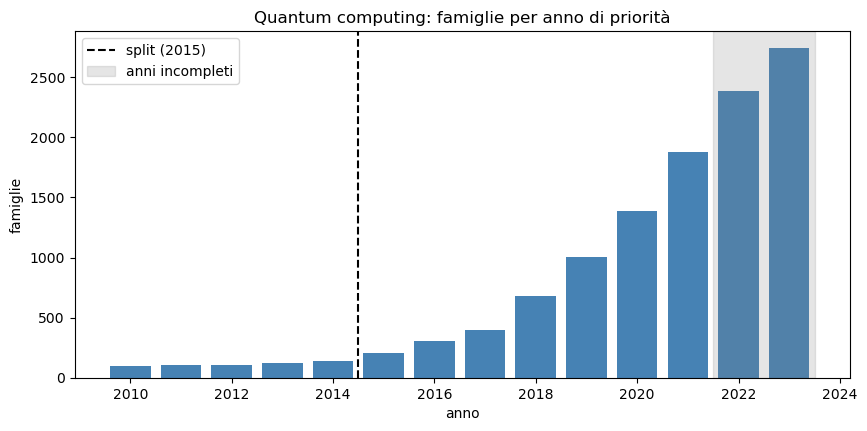

In [13]:
SPLIT_RULE = "crescita"              # "crescita", "quota" o "manuale"
SHARE_THRESHOLD = 0.25               # per la regola "quota"
SPLIT_MANUAL = 2017                  # per la regola "manuale"

families = overview["famiglie"].reindex(range(YEAR_MIN, YEAR_MAX + 1), fill_value=0)
complete = families.loc[:LAST_COMPLETE_YEAR]

growth = complete.pct_change().replace([np.inf, -np.inf], np.nan)      # crescita annua
growth_smooth = growth.rolling(3, center=True, min_periods=2).mean()   # media mobile su 3 anni
share_cum = complete.cumsum() / complete.sum()                          # quota cumulata

candidates = {
    "crescita": growth_smooth[growth_smooth > growth.mean()].index.min(),
    "quota": share_cum[share_cum >= SHARE_THRESHOLD].index.min(),
    "manuale": SPLIT_MANUAL,
}
SPLIT_YEAR = int(candidates[SPLIT_RULE])

display(pd.DataFrame({"famiglie": complete, "crescita annua (%)": (growth * 100).round(1),
                      "crescita media mobile (%)": (growth_smooth * 100).round(1),
                      "quota cumulata (%)": (share_cum * 100).round(1)}).T)
print("Anno di split secondo ciascuna regola:", {k: int(v) for k, v in candidates.items()})
print(f"Regola scelta: {SPLIT_RULE} -> SPLIT_YEAR = {SPLIT_YEAR}")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(families.index, families.values, color="steelblue")
ax.axvline(SPLIT_YEAR - 0.5, color="black", ls="--", label=f"split ({SPLIT_YEAR})")
ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.2, label="anni incompleti")
ax.set(title="Quantum computing: famiglie per anno di priorità", xlabel="anno", ylabel="famiglie")
ax.legend()
plt.show()

## 6. Funzioni delle metriche

Copiate dal notebook 11 (sezione 3). Ogni funzione riceve `patents_per_firm`, la lista del numero di famiglie di ciascun applicant. In più c'è `plot_yearly`, che disegna una metrica anno per anno.

In [14]:
def concentration_ratio(patents_per_firm, k):
    "Share (%) of all patents held by the k largest firms."
    largest_first = np.sort(patents_per_firm)[::-1]
    return largest_first[:k].sum() / largest_first.sum() * 100


def herfindahl(patents_per_firm):
    "Sum of the squared shares of the firms."
    shares = np.asarray(patents_per_firm) / np.sum(patents_per_firm)
    return np.sum(shares ** 2)


def coefficient_of_variation(patents_per_firm):
    "Standard deviation of patents per firm divided by their mean."
    x = np.asarray(patents_per_firm, dtype=float)
    return x.std(ddof=1) / x.mean()


def lorenz_curve(patents_per_firm):
    "Cumulative share of firms (smallest first) and cumulative share of their patents."
    x = np.sort(patents_per_firm)                     # smallest firms first
    share_of_firms = np.arange(0, len(x) + 1) / len(x)
    share_of_patents = np.concatenate([[0], np.cumsum(x) / x.sum()])
    return share_of_firms, share_of_patents


def gini(patents_per_firm):
    "Area between the diagonal and the Lorenz curve, divided by the area below the diagonal (= 0.5)."
    share_of_firms, share_of_patents = lorenz_curve(patents_per_firm)
    widths = np.diff(share_of_firms)
    heights = (share_of_patents[1:] + share_of_patents[:-1]) / 2
    area_below_curve = np.sum(widths * heights)
    return (0.5 - area_below_curve) / 0.5


def lotka(patents_per_firm):
    "Slope (and its p-value) of log(number of firms with n patents) on log(n)."
    f = pd.Series(patents_per_firm).value_counts().sort_index()   # n -> number of firms with n patents
    if len(f) < 3:                                                 # too few points to fit a line
        return np.nan, np.nan
    fit = stats.linregress(np.log(f.index), np.log(f.values))
    return fit.slope, fit.pvalue


def plot_yearly(series, title, ylabel, percent=False):
    "Una metrica anno per anno, con l'anno di split e gli anni incompleti evidenziati."
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(series.index, series.values, marker="o", color="steelblue")
    ax.axvline(SPLIT_YEAR - 0.5, color="black", ls="--", label=f"split ({SPLIT_YEAR})")
    ax.axvspan(LAST_COMPLETE_YEAR + 0.5, YEAR_MAX + 0.5, color="grey", alpha=0.2, label="anni incompleti")
    if percent:
        ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.set(title=title, xlabel="anno", ylabel=ylabel)
    ax.legend()
    plt.show()

## 7. CR4 per anno

Quota delle famiglie dell'anno detenuta dai 4 applicant più grandi. Gli anni con pochi applicant hanno un CR4 alto per costruzione.

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
CR4 (%),8.2,6.1,11.3,22.9,13.1,16.1,21.4,22.4,21.4,19.3,14.6,15.7,14.4,18.3


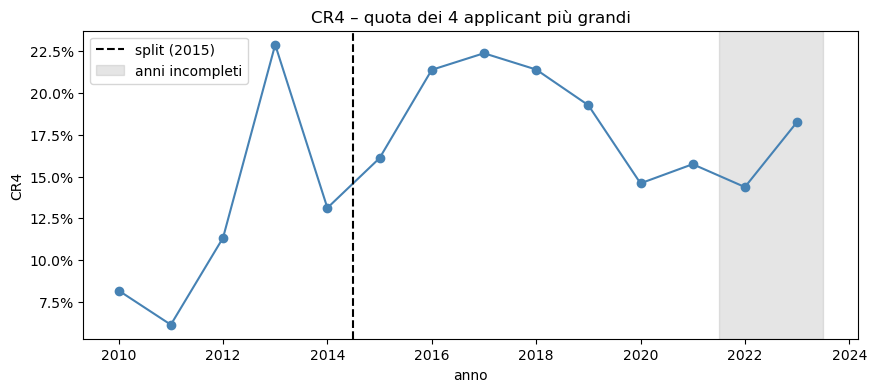

In [15]:
cr4 = pd.Series({y: concentration_ratio(x, 4) for y, x in yearly.items()}, name="CR4 (%)")
display(cr4.round(1).to_frame().T)
plot_yearly(cr4, "CR4 – quota dei 4 applicant più grandi", "CR4", percent=True)

## 8. CR8 per anno

Quota delle famiglie dell'anno detenuta dagli 8 applicant più grandi.

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
CR8 (%),14.9,10.4,18.2,32.8,21.3,24.3,31.0,35.8,30.2,27.8,19.6,21.2,20.3,23.5


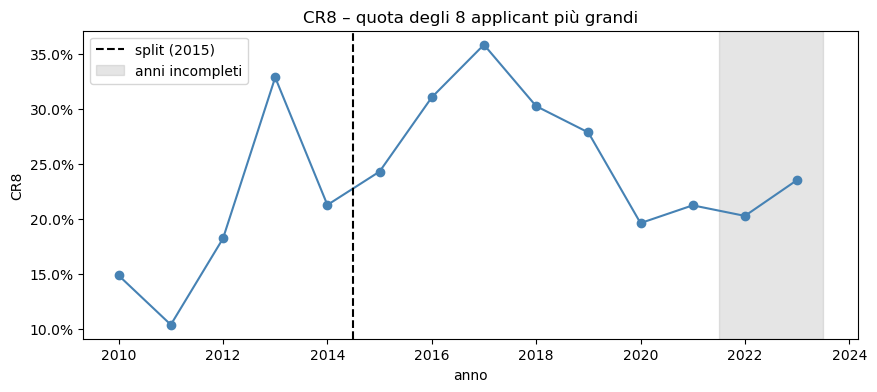

In [16]:
cr8 = pd.Series({y: concentration_ratio(x, 8) for y, x in yearly.items()}, name="CR8 (%)")
display(cr8.round(1).to_frame().T)
plot_yearly(cr8, "CR8 – quota degli 8 applicant più grandi", "CR8", percent=True)

## 9. Indice di Herfindahl (HH) per anno

Somma dei quadrati delle quote: 1 se un solo applicant ha tutte le famiglie, 1/N se gli N applicant sono uguali. Un HH che cresce nel tempo indica consolidamento.

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
HH,0.0067,0.0045,0.01,0.0217,0.011,0.0138,0.023,0.0207,0.0174,0.0153,0.0093,0.0116,0.0086,0.0134


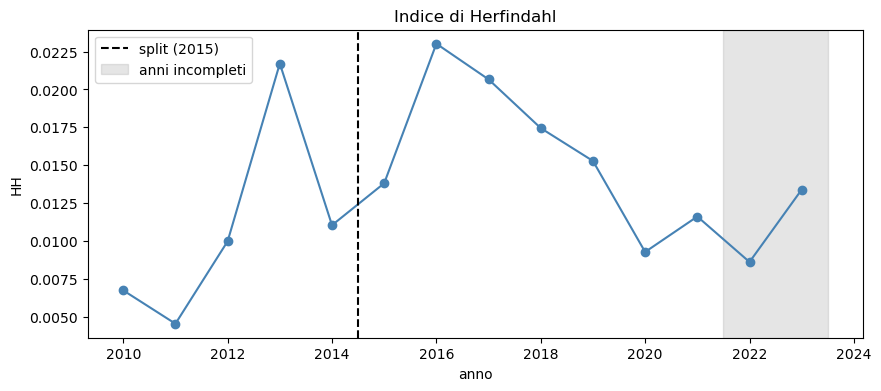

In [17]:
hh = pd.Series({y: herfindahl(x) for y, x in yearly.items()}, name="HH")
display(hh.round(4).to_frame().T)
plot_yearly(hh, "Indice di Herfindahl", "HH")

## 10. Numbers-equivalent (1/HH) per anno

Numero di applicant di uguale dimensione che darebbero lo stesso HH. Un 1/HH che scende nel tempo indica consolidamento.

,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
1/HH,148.6,220.8,100.3,46.1,90.6,72.4,43.4,48.4,57.3,65.5,107.9,86.2,116.2,74.7


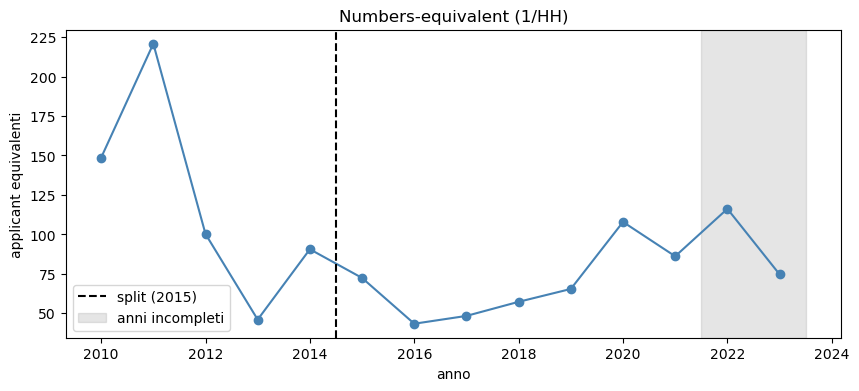

In [18]:
inv_hh = (1 / hh).rename("1/HH")
display(inv_hh.round(1).to_frame().T)
plot_yearly(inv_hh, "Numbers-equivalent (1/HH)", "applicant equivalenti")

# tabella riassuntiva delle metriche annuali
yearly_metrics = pd.concat([overview["applicant attivi"], cr4, cr8, hh, inv_hh], axis=1)
yearly_metrics.to_csv(OUTPUT_DIR / "concentration_by_year.csv")

## 11. Coefficiente di variazione (CV), tutto il periodo

Deviazione standard delle famiglie per applicant divisa per la media: misura quanto gli applicant sono diversi fra loro, indipendentemente dalla loro dimensione.

In [19]:
x_all = total.to_numpy()                 # famiglie per applicant, YEAR_MIN-YEAR_MAX
cv = coefficient_of_variation(x_all)
print(f"Applicant: {len(x_all):,} | famiglie per applicant: media {x_all.mean():.2f}, "
      f"mediana {np.median(x_all):.0f}, max {x_all.max()}")
print(f"CV {YEAR_MIN}-{YEAR_MAX}: {cv:.3f}")

Applicant: 4,013 | famiglie per applicant: media 4.09, mediana 1, max 744
CV 2010-2023: 4.985


## 12. Curva di Lorenz e indice di Gini, tutto il periodo

Un punto della curva si legge così: "il x% più piccolo degli applicant detiene il y% delle famiglie". Il Gini è l'area fra diagonale e curva divisa per l'area sotto la diagonale: 0 se tutti gli applicant sono uguali, vicino a 1 se uno ha quasi tutto.

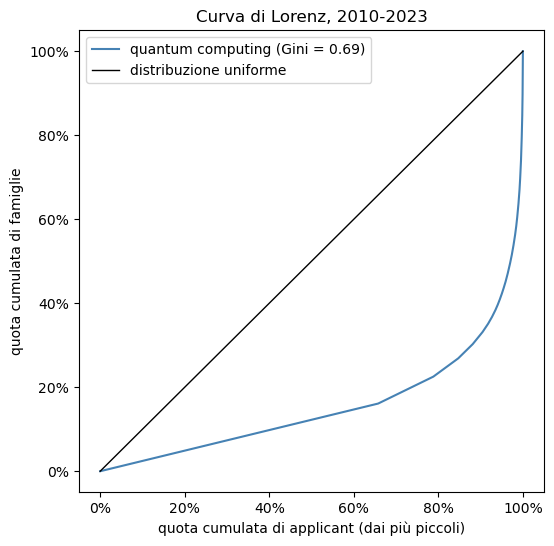

Gini 2010-2023: 0.691


In [20]:
share_of_firms, share_of_patents = lorenz_curve(x_all)
g = gini(x_all)

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(share_of_firms, share_of_patents, color="steelblue", label=f"quantum computing (Gini = {g:.2f})")
ax.plot([0, 1], [0, 1], color="black", lw=1, label="distribuzione uniforme")
ax.set(title=f"Curva di Lorenz, {YEAR_MIN}-{YEAR_MAX}",
       xlabel="quota cumulata di applicant (dai più piccoli)", ylabel="quota cumulata di famiglie")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.legend()
plt.show()

print(f"Gini {YEAR_MIN}-{YEAR_MAX}: {g:.3f}")

## 13. Coefficiente di Lotka, tutto il periodo

Pendenza L della retta log f(n) = c + L·log n, dove f(n) è il numero di applicant con esattamente n famiglie. La legge di Lotka prevede L = −2: più L è vicino a 0, più ci sono applicant con molte famiglie, quindi più il settore è concentrato. La tabella confronta gli applicant osservati con quelli previsti da f(1)/n².

Lotka L 2010-2023: -1.154 (p-value 0.0000) | valore teorico: -2


,applicant osservati,applicant previsti (f(1)/n²)
famiglie per applicant (n),,
1,2635,2635.0
2,524,658.8
3,235,292.8
4,137,164.7
5,93,105.4
6,52,73.2
7,36,53.8
8,31,41.2
9,21,32.5


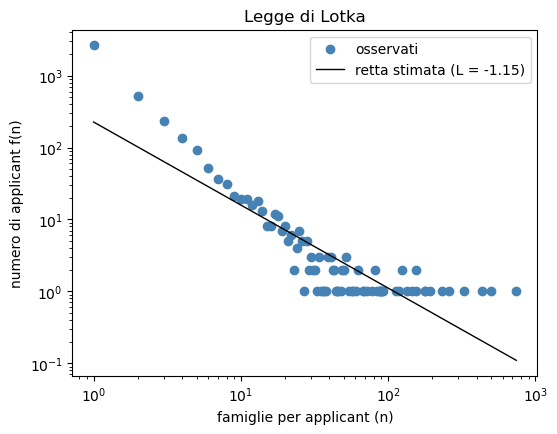

In [21]:
L, p_value = lotka(x_all)
print(f"Lotka L {YEAR_MIN}-{YEAR_MAX}: {L:.3f} (p-value {p_value:.4f}) | valore teorico: -2")

observed = pd.Series(x_all).value_counts().sort_index()
lotka_check = pd.DataFrame({
    "applicant osservati": observed,
    "applicant previsti (f(1)/n²)": observed.get(1, 0) / observed.index.to_numpy() ** 2,
})
lotka_check.index.name = "famiglie per applicant (n)"
display(lotka_check.head(10).round(1))

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(observed.index, observed.values, color="steelblue", label="osservati")
n = observed.index.to_numpy()
ax.plot(n, np.exp(np.log(observed.values).mean() - L * np.log(n).mean()) * n ** L,
        color="black", lw=1, label=f"retta stimata (L = {L:.2f})")
ax.set(xscale="log", yscale="log", title="Legge di Lotka", xlabel="famiglie per applicant (n)",
       ylabel="numero di applicant f(n)")
ax.legend()
plt.show()

pd.Series({"applicant": len(x_all), "famiglie per applicant (somma)": int(x_all.sum()),
           "CV": cv, "Gini": g, "Lotka L": L, "Lotka p-value": p_value},
          name=f"{YEAR_MIN}-{YEAR_MAX}").to_csv(OUTPUT_DIR / "concentration_all_years.csv")